# Tercera parte: implementación

Max-Cut ponderado con balance, Must-Link y Cannot-Link. Se genera una instancia aleatoria reproducible, se construye su QUBO y se resuelve **primero por fuerza bruta y después mediante `SimulatedAnnealingSampler`**. Para ambos métodos se muestran energía, tamaños de las particiones, peso del corte y violaciones, junto con los gráficos antes y después.

## Librerías

In [1]:
%matplotlib inline

import random
from itertools import combinations, product

import dimod
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Markdown, display
from dwave.samplers import SimulatedAnnealingSampler


## 1. Generar un grafo aleatorio ponderado de tamaño n

Cada posible arista aparece con probabilidad `p`; sus pesos son enteros positivos entre `peso_min` y `peso_max`. Se añaden los `n` nodos aunque alguno quede aislado.

In [2]:
def generar_grafo_ponderado(n, p=0.5, peso_min=1, peso_max=10, seed=None):
    if n < 2:
        raise ValueError("n debe ser al menos 2.")
    if not 0 <= p <= 1:
        raise ValueError("p debe estar entre 0 y 1.")
    if not 1 <= peso_min <= peso_max:
        raise ValueError("Los límites de los pesos deben ser positivos y ordenados.")

    rng = random.Random(seed)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    for i, j in combinations(G.nodes, 2):
        if rng.random() < p:
            G.add_edge(i, j, weight=rng.randint(peso_min, peso_max))
    return G


## 2. Seleccionar pares Must-Link y Cannot-Link aleatorios

Se eligen entre todos los nodos, aunque no exista una arista entre ellos. Los pares no se repiten ni se asignan a ambos tipos. Puede haber contradicciones indirectas o incompatibilidad con el balance; la fuerza bruta comprobará si existe alguna asignación que cumpla todo.

In [3]:
def seleccionar_restricciones(G, n_must=3, n_cannot=3, seed=None):
    pares = list(combinations(sorted(G.nodes), 2))
    if n_must < 0 or n_cannot < 0:
        raise ValueError("El número de restricciones no puede ser negativo.")
    if n_must + n_cannot > len(pares):
        raise ValueError("No hay suficientes pares distintos para esas restricciones.")

    rng = random.Random(seed)
    elegidos = rng.sample(pares, n_must + n_cannot)
    return elegidos[:n_must], elegidos[n_must:]


# Cambia aquí los parámetros de la instancia.
n = 20
p = 0.5
peso_min, peso_max = 1, 10
n_must, n_cannot = 3, 3
seed = 42
num_reads = 500

G = generar_grafo_ponderado(n, p, peso_min, peso_max, seed=seed)
node_order = sorted(G.nodes)
must_link, cannot_link = seleccionar_restricciones(
    G, n_must, n_cannot, seed=seed + 1
)

# El peso total acota la variación del objetivo del corte.
peso_total = sum(data["weight"] for _, _, data in G.edges(data=True))
A = B = C = peso_total + 1.0

print(f"Nodos: {G.number_of_nodes()} | Aristas: {G.number_of_edges()}")
print(f"Peso total del grafo: {peso_total}")
print("Must-Link:", must_link)
print("Cannot-Link:", cannot_link)
print(f"A = {A}, B = {B}, C = {C}")


Nodos: 20 | Aristas: 96
Peso total del grafo: 541
Must-Link: [(0, 10), (4, 8), (14, 18)]
Cannot-Link: [(1, 19), (7, 14), (5, 15)]
A = 542.0, B = 542.0, C = 542.0


## 3. Construir el diccionario QUBO

Se mantiene el objetivo **Max-Cut** del ejemplo inicial, ahora ponderado:

$$E(x)=-\sum_{(i,j)\in E}w_{ij}(x_i-x_j)^2
+A\left(\sum_i x_i-\frac{n}{2}\right)^2
+B\sum_{(i,j)\in\mathcal M}(x_i-x_j)^2
-C\sum_{(i,j)\in\mathcal C}(x_i-x_j)^2.$$

Para variables binarias, $(x_i-x_j)^2=x_i+x_j-2x_ix_j$. Cada pareja aparece una sola vez en `Q` y la constante del balance se conserva en `offset`. El término Cannot-Link vale $-C$ por par satisfecho, tal como en el enunciado.

Se eligen $A=B=C>\sum w_{ij}$ para priorizar las restricciones cuando existe una partición que las cumple. Con un número impar de nodos, balance significa que los tamaños difieren en uno; su energía mínima es entonces $A/4$.

In [4]:
def construir_qubo(G, must_link, cannot_link, A, B, C):
    nodes = sorted(G.nodes)
    n = len(nodes)
    if min(A, B, C) <= 0:
        raise ValueError("A, B y C deben ser positivos.")
    for i, j in must_link + cannot_link:
        if i not in G or j not in G or i == j:
            raise ValueError(f"Par de restricción no válido: {(i, j)}")

    Q = {(i, i): 0.0 for i in nodes}

    def add_Q(i, j, value):
        key = (min(i, j), max(i, j))
        Q[key] = Q.get(key, 0.0) + value

    # Corte ponderado: -w_ij * (x_i - x_j)**2
    for i, j, data in G.edges(data=True):
        w = data["weight"]
        add_Q(i, i, -w)
        add_Q(j, j, -w)
        add_Q(i, j, 2 * w)

    # Balance: A * (sum(x_i) - n/2)**2
    for i in nodes:
        add_Q(i, i, A * (1 - n))
    for i, j in combinations(nodes, 2):
        add_Q(i, j, 2 * A)
    offset = A * (n / 2)**2

    # Must-Link: B * (x_i - x_j)**2
    for i, j in must_link:
        add_Q(i, i, B)
        add_Q(j, j, B)
        add_Q(i, j, -2 * B)

    # Cannot-Link: -C * (x_i - x_j)**2
    for i, j in cannot_link:
        add_Q(i, i, -C)
        add_Q(j, j, -C)
        add_Q(i, j, 2 * C)

    return Q, offset


Q, offset = construir_qubo(G, must_link, cannot_link, A, B, C)
bqm = dimod.BinaryQuadraticModel.from_qubo(Q, offset=offset)
print(f"QUBO construido: {len(bqm.variables)} variables, offset = {offset:.2f}")
print("Diccionario Q:")
print(Q)


QUBO construido: 20 variables, offset = 54200.00
Diccionario Q:
{(0, 0): -9796.0, (1, 1): -10886.0, (2, 2): -10367.0, (3, 3): -10372.0, (4, 4): -9797.0, (5, 5): -10883.0, (6, 6): -10351.0, (7, 7): -10896.0, (8, 8): -9809.0, (9, 9): -10341.0, (10, 10): -9823.0, (11, 11): -10358.0, (12, 12): -10360.0, (13, 13): -10339.0, (14, 14): -10360.0, (15, 15): -10903.0, (16, 16): -10360.0, (17, 17): -10335.0, (18, 18): -9803.0, (19, 19): -10903.0, (0, 2): 1094.0, (0, 3): 1090.0, (0, 7): 1098.0, (0, 8): 1088.0, (0, 9): 1102.0, (0, 14): 1100.0, (0, 17): 1090.0, (0, 19): 1090.0, (1, 2): 1096.0, (1, 3): 1098.0, (1, 4): 1096.0, (1, 10): 1102.0, (1, 11): 1104.0, (1, 13): 1092.0, (1, 15): 1092.0, (2, 3): 1100.0, (2, 5): 1096.0, (2, 6): 1094.0, (2, 9): 1090.0, (2, 11): 1100.0, (2, 12): 1102.0, (2, 13): 1096.0, (2, 16): 1086.0, (2, 18): 1088.0, (2, 19): 1104.0, (3, 5): 1100.0, (3, 6): 1100.0, (3, 7): 1090.0, (3, 8): 1102.0, (3, 11): 1104.0, (3, 12): 1092.0, (3, 14): 1100.0, (3, 15): 1086.0, (3, 17): 1090.0

## Funciones para evaluar y visualizar

Se cuentan por separado las violaciones Must-Link, Cannot-Link y del balance (0 si los tamaños difieren como máximo en uno, 1 en otro caso). El total suma esos tres valores. Todas las figuras usan las mismas posiciones y muestran los pesos de las aristas.

In [5]:
def evaluar_solucion(G, x, must_link, cannot_link, A, B, C):
    grupo_0 = [i for i in sorted(G.nodes) if x[i] == 0]
    grupo_1 = [i for i in sorted(G.nodes) if x[i] == 1]
    corte = sum(
        data["weight"] for i, j, data in G.edges(data=True) if x[i] != x[j]
    )
    v_must = sum(x[i] != x[j] for i, j in must_link)
    v_cannot = sum(x[i] == x[j] for i, j in cannot_link)
    v_balance = int(abs(len(grupo_0) - len(grupo_1)) > 1)
    E_balance = A * (len(grupo_1) - len(G) / 2)**2
    E_must = B * v_must
    E_cannot = -C * (len(cannot_link) - v_cannot)
    return {
        "grupo_0": grupo_0, "grupo_1": grupo_1,
        "peso_corte": corte,
        "v_balance": v_balance, "v_must": v_must, "v_cannot": v_cannot,
        "violaciones": v_balance + v_must + v_cannot,
        "energia": -corte + E_balance + E_must + E_cannot,
    }


def mostrar_resultado(nombre, G, x, energia, must_link, cannot_link, A, B, C):
    r = evaluar_solucion(G, x, must_link, cannot_link, A, B, C)
    print(f"--- {nombre} ---")
    print("Asignación:", "".join(str(x[i]) for i in sorted(G.nodes)))
    print(f"Energía mínima encontrada: {energia:.2f}")
    print(f"Tamaños de las particiones: {len(r['grupo_0'])} y {len(r['grupo_1'])}")
    print("Grupo 0:", r["grupo_0"])
    print("Grupo 1:", r["grupo_1"])
    print(f"Peso total del corte: {r['peso_corte']}")
    print(f"Violaciones Must-Link: {r['v_must']}")
    print(f"Violaciones Cannot-Link: {r['v_cannot']}")
    print(f"Violaciones de balance: {r['v_balance']}")
    print(f"Violaciones totales: {r['violaciones']}")
    return r


def dibujar_grafo(G, pos, titulo, x=None):
    nodes = sorted(G.nodes)
    fig, ax = plt.subplots(figsize=(9, 6))
    colores = ["lightgray" if x is None else
               ("skyblue" if x[i] == 0 else "salmon") for i in nodes]
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=colores,
                           node_size=700, ax=ax)
    nx.draw_networkx_labels(G, pos, font_weight="bold", ax=ax)
    cortadas = [] if x is None else [(i, j) for i, j in G.edges if x[i] != x[j]]
    no_cortadas = list(G.edges) if x is None else [
        (i, j) for i, j in G.edges if x[i] == x[j]
    ]
    nx.draw_networkx_edges(G, pos, edgelist=no_cortadas,
                           edge_color="gray", width=1.5, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=cortadas,
                           edge_color="black", style="dashed", width=3, ax=ax)
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=nx.get_edge_attributes(G, "weight"),
        font_size=9, ax=ax,
    )
    if x is not None:
        ax.legend(handles=[
            Patch(facecolor="skyblue", label="Grupo 0"),
            Patch(facecolor="salmon", label="Grupo 1"),
            Line2D([0], [0], color="black", linestyle="--", label="Arista cortada"),
        ])
    ax.set_title(titulo)
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()


## Grafo antes de la optimización

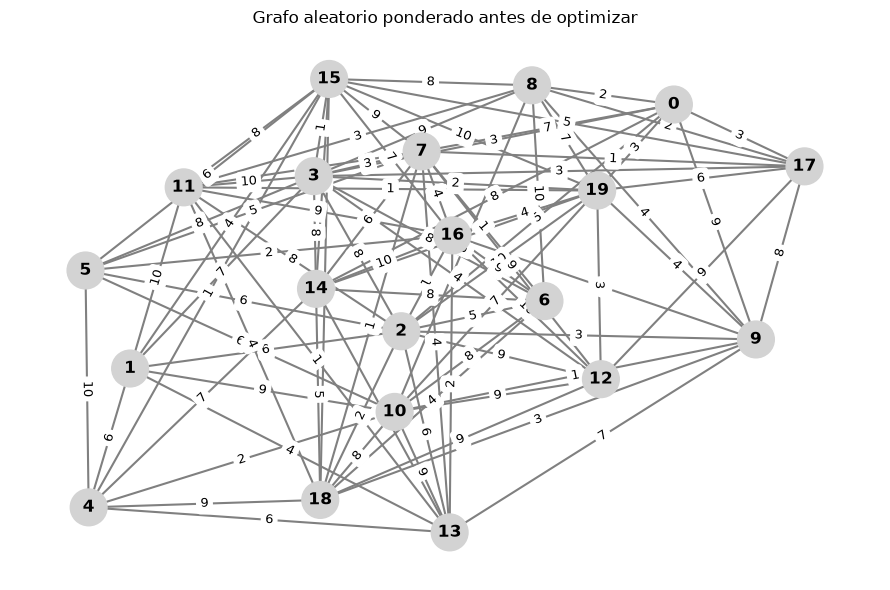

In [6]:
pos = nx.spring_layout(G, seed=seed)
dibujar_grafo(G, pos, "Grafo aleatorio ponderado antes de optimizar")


## 4.a. Primero: resolver mediante fuerza bruta

Se examinan las $2^n$ asignaciones sin almacenarlas todas. Se obtiene el mínimo global del QUBO y se cuenta cuántas asignaciones cumplen todas las restricciones. El ejemplo usa `n = 8` (256 asignaciones); el coste crece exponencialmente.

In [7]:
def resolver_fuerza_bruta(bqm, must_link, cannot_link):
    nodes = sorted(bqm.variables)
    energia_minima = float("inf")
    mejor_x = None
    n_factibles = 0

    for bits in product([0, 1], repeat=len(nodes)):
        x = dict(zip(nodes, bits))
        energia = bqm.energy(x)
        if energia < energia_minima:
            energia_minima = energia
            mejor_x = x.copy()

        balance_ok = abs(len(nodes) - 2 * sum(bits)) <= 1
        if (balance_ok
            and all(x[i] == x[j] for i, j in must_link)
            and all(x[i] != x[j] for i, j in cannot_link)):
            n_factibles += 1

    return mejor_x, energia_minima, n_factibles


x_bruta, energia_bruta, n_factibles = resolver_fuerza_bruta(
    bqm, must_link, cannot_link
)
print(f"Asignaciones evaluadas: {2**n}")
print(f"Asignaciones que cumplen todas las restricciones: {n_factibles}")
if n_factibles == 0:
    print("Las restricciones no pueden cumplirse todas simultáneamente.")

resultado_bruta = mostrar_resultado(
    "Fuerza bruta", G, x_bruta, energia_bruta, must_link, cannot_link, A, B, C
)


Asignaciones evaluadas: 1048576
Asignaciones que cumplen todas las restricciones: 2976
--- Fuerza bruta ---
Asignación: 00010110010111100011
Energía mínima encontrada: -1980.00
Tamaños de las particiones: 10 y 10
Grupo 0: [0, 1, 2, 4, 7, 8, 10, 15, 16, 17]
Grupo 1: [3, 5, 6, 9, 11, 12, 13, 14, 18, 19]
Peso total del corte: 354
Violaciones Must-Link: 0
Violaciones Cannot-Link: 0
Violaciones de balance: 0
Violaciones totales: 0


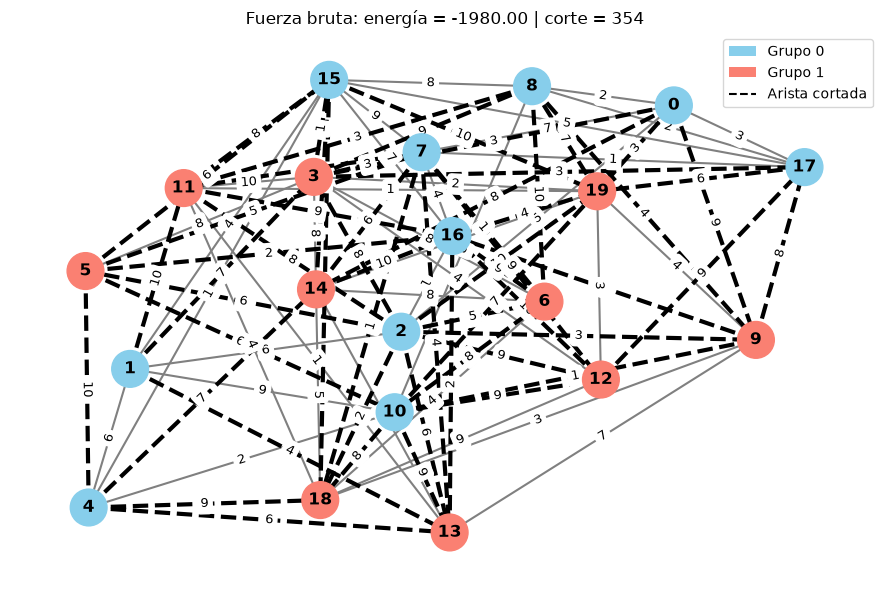

In [8]:
dibujar_grafo(
    G, pos,
    f"Fuerza bruta: energía = {energia_bruta:.2f} | corte = {resultado_bruta['peso_corte']}",
    x=x_bruta,
)


## 4.b. Después: resolver mediante SimulatedAnnealingSampler

Se usa el mismo QUBO. La energía mínima encontrada entre las lecturas se compara con el óptimo exacto; el annealing es heurístico y no garantiza alcanzarlo.

In [9]:
sampler = SimulatedAnnealingSampler()
sampleset = sampler.sample(bqm, num_reads=num_reads, seed=seed)
x_sa = dict(sampleset.first.sample)
energia_sa = sampleset.first.energy

resultado_sa = mostrar_resultado(
    "Simulated Annealing", G, x_sa, energia_sa, must_link, cannot_link, A, B, C
)


--- Simulated Annealing ---
Asignación: 01000110010111100110
Energía mínima encontrada: -1972.00
Tamaños de las particiones: 10 y 10
Grupo 0: [0, 2, 3, 4, 7, 8, 10, 15, 16, 19]
Grupo 1: [1, 5, 6, 9, 11, 12, 13, 14, 17, 18]
Peso total del corte: 346
Violaciones Must-Link: 0
Violaciones Cannot-Link: 0
Violaciones de balance: 0
Violaciones totales: 0


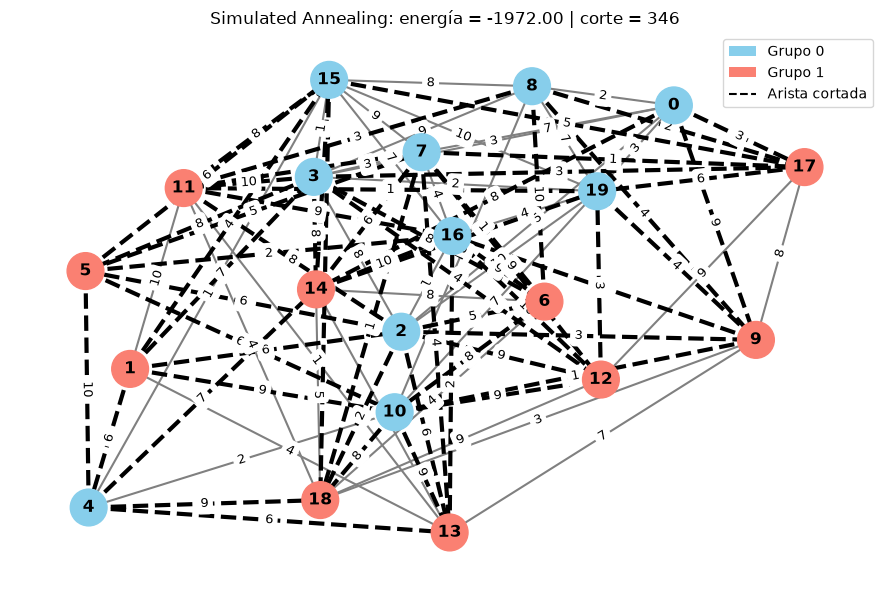

In [10]:
dibujar_grafo(
    G, pos,
    f"Simulated Annealing: energía = {energia_sa:.2f} | corte = {resultado_sa['peso_corte']}",
    x=x_sa,
)

## 5. Comparar las métricas de ambos métodos

Los resultados individuales muestran todos los datos solicitados. La tabla los reúne para comparar. Dos asignaciones distintas pueden compartir la misma energía mínima.

In [11]:
filas = [
    ("Energía mínima", f"{energia_bruta:.2f}", f"{energia_sa:.2f}"),
    ("Tamaños de particiones",
     f"{len(resultado_bruta['grupo_0'])} / {len(resultado_bruta['grupo_1'])}",
     f"{len(resultado_sa['grupo_0'])} / {len(resultado_sa['grupo_1'])}"),
    ("Peso total del corte", resultado_bruta["peso_corte"], resultado_sa["peso_corte"]),
    ("Violaciones Must-Link", resultado_bruta["v_must"], resultado_sa["v_must"]),
    ("Violaciones Cannot-Link", resultado_bruta["v_cannot"], resultado_sa["v_cannot"]),
    ("Violaciones de balance", resultado_bruta["v_balance"], resultado_sa["v_balance"]),
    ("Violaciones totales", resultado_bruta["violaciones"], resultado_sa["violaciones"]),
]
tabla = "| Métrica | Fuerza bruta | Simulated Annealing |\n|---|---:|---:|\n"
tabla += "\n".join(f"| {metrica} | {bruta} | {sa} |" for metrica, bruta, sa in filas)
display(Markdown(tabla))

diferencia = energia_sa - energia_bruta
print(f"Diferencia de energía respecto al óptimo: {diferencia:.6f}")
print("¿Annealing alcanzó el óptimo?", abs(diferencia) < 1e-8)


| Métrica | Fuerza bruta | Simulated Annealing |
|---|---:|---:|
| Energía mínima | -1980.00 | -1972.00 |
| Tamaños de particiones | 10 / 10 | 10 / 10 |
| Peso total del corte | 354 | 346 |
| Violaciones Must-Link | 0 | 0 |
| Violaciones Cannot-Link | 0 | 0 |
| Violaciones de balance | 0 | 0 |
| Violaciones totales | 0 | 0 |

Diferencia de energía respecto al óptimo: 8.000000
¿Annealing alcanzó el óptimo? False


## 6. Visualización antes y después

Las tres figuras anteriores muestran el grafo original y las soluciones de fuerza bruta y simulated annealing con las mismas posiciones. Los números sobre las aristas son sus pesos; los colores identifican la partición y las líneas negras discontinuas muestran las aristas cortadas.

# Cuarta parte: análisis

## 1. Influencia de A, B y C en la calidad de la solución

La calidad se evalúa mediante **cumplimiento de restricciones y peso del corte**, además de la energía mínima del mismo QUBO.

- **A** controla el balance. Para ocho nodos, las particiones 4/4, 3/5 y 2/6 aportan respectivamente $0$, $A$ y $4A$ a la energía.
- **B** añade un coste $B$ por cada Must-Link incumplido.
- **C** recompensa con $-C$ cada Cannot-Link satisfecho. Equivalentemente, añade un coste $C$ por cada violación y una constante $-C|\mathcal C|$.

Si un peso es pequeño, puede compensar incumplir su restricción para mejorar el corte. Por ejemplo, ganar 12 unidades de corte incumpliendo un Must-Link cuesta $-12+B$, si los demás términos no cambian. Con $B=5$ la energía baja; con $B=20$ sube.

No es obligatorio que $A=B=C$. Se igualaron en la implementación como una elección inicial. Cuando las restricciones son compatibles, elegir los tres por encima de la suma de pesos del grafo basta para priorizar su cumplimiento. Si son incompatibles, aumentar los pesos no crea una solución factible.

**Precaución al interpretar la energía:** cambiar los coeficientes cambia la función objetivo. En particular, aumentar $C$ reduce la energía de los pares satisfechos aunque la partición no cambie. Una energía más negativa entre distintos QUBO no implica por sí sola una solución de mayor calidad.

## Preparación de los experimentos

Se reutilizan las funciones de la tercera parte. Las instancias y semillas de esta sección son independientes del ejemplo original. Las tablas muestran tanto el número de aristas cortadas como su peso total.

In [12]:
from math import isclose
from statistics import median
from time import perf_counter


def tabla_analisis(cabeceras, filas):
    texto = "| " + " | ".join(cabeceras) + " |\n"
    texto += "|" + "|".join(["---"] * len(cabeceras)) + "|\n"
    texto += "\n".join("| " + " | ".join(map(str, fila)) + " |" for fila in filas)
    display(Markdown(texto))


def instancia_analisis(n_inst, semilla, n_must_inst=3, n_cannot_inst=3):
    grafo = generar_grafo_ponderado(n_inst, p=0.5, peso_min=1, peso_max=10, seed=semilla)
    ml, cl = seleccionar_restricciones(
        grafo, n_must_inst, n_cannot_inst, seed=semilla + 1
    )
    return grafo, ml, cl


def modelo_analisis(grafo, ml, cl, a, b, c):
    q, constante = construir_qubo(grafo, ml, cl, a, b, c)
    return dimod.BinaryQuadraticModel.from_qubo(q, offset=constante)


def metricas_analisis(grafo, ml, cl, a, b, c, x, energia):
    r = evaluar_solucion(grafo, x, ml, cl, a, b, c)
    assert isclose(r["energia"], energia, abs_tol=1e-7)
    r["energia"] = float(energia)
    r["aristas_cortadas"] = sum(x[i] != x[j] for i, j in grafo.edges)
    r["desbalance"] = abs(len(r["grupo_0"]) - len(r["grupo_1"]))
    r["tamanos"] = f"{len(r['grupo_0'])}/{len(r['grupo_1'])}"
    return r


## 2. Qué ocurre cuando A, B o C son insuficientes

Se varía **un único coeficiente cada vez** y se mantienen los otros dos en $P=1+\sum w_{ij}$. Se usa fuerza bruta para separar los efectos de las penalizaciones de los posibles errores del annealing.

En el grafo original (semilla 42), reducir A no provoca desbalance: ese efecto depende de la instancia. Por eso se incluye la **semilla 10 para ilustrar A bajo**; las semillas de todos los experimentos quedan explícitas. Para B y C se usa la semilla 42. En cada barrido se conserva el mismo grafo y las mismas restricciones.

In [13]:
factores_penalizacion = [0.001, 0.01, 0.1, 1.0, 2.0]
semillas_parametros = {"A": 10, "B": 42, "C": 42}
analisis_parametros = []

for parametro, semilla_param in semillas_parametros.items():
    grafo_p, ml_p, cl_p = instancia_analisis(8, semilla_param)
    P = 1.0 + sum(d["weight"] for _, _, d in grafo_p.edges(data=True))
    filas_param = []
    for factor in factores_penalizacion:
        coef = {"A": P, "B": P, "C": P}
        coef[parametro] = factor * P
        modelo_p = modelo_analisis(grafo_p, ml_p, cl_p, coef["A"], coef["B"], coef["C"])
        xp, ep, fp = resolver_fuerza_bruta(modelo_p, ml_p, cl_p)
        rp = metricas_analisis(grafo_p, ml_p, cl_p, coef["A"], coef["B"], coef["C"], xp, ep)
        rp.update(parametro=parametro, semilla=semilla_param, factor=factor,
                  coeficiente=coef[parametro], factibles=fp)
        analisis_parametros.append(rp)
        filas_param.append([
            f"{factor:g}", f"{coef[parametro]:.3f}", f"{ep:.3f}", rp["tamanos"],
            rp["aristas_cortadas"], rp["peso_corte"], rp["v_balance"], rp["v_must"], rp["v_cannot"],
        ])
    display(Markdown(f"### Barrido de {parametro}: semilla {semilla_param}, P = {P:g}"))
    tabla_analisis(
        ["Factor de P", parametro, "E mínima", "Tamaños", "Aristas cortadas",
         "Peso corte", "V. balance", "V. Must", "V. Cannot"], filas_param
    )


### Barrido de A: semilla 10, P = 98

| Factor de P | A | E mínima | Tamaños | Aristas cortadas | Peso corte | V. balance | V. Must | V. Cannot |
|---|---|---|---|---|---|---|---|---|
| 0.001 | 0.098 | -356.902 | 3/5 | 10 | 63 | 1 | 0 | 0 |
| 0.01 | 0.980 | -356.020 | 3/5 | 10 | 63 | 1 | 0 | 0 |
| 0.1 | 9.800 | -347.200 | 3/5 | 10 | 63 | 1 | 0 | 0 |
| 1 | 98.000 | -343.000 | 4/4 | 9 | 49 | 0 | 0 | 0 |
| 2 | 196.000 | -343.000 | 4/4 | 9 | 49 | 0 | 0 | 0 |

### Barrido de B: semilla 42, P = 69

| Factor de P | B | E mínima | Tamaños | Aristas cortadas | Peso corte | V. balance | V. Must | V. Cannot |
|---|---|---|---|---|---|---|---|---|
| 0.001 | 0.069 | -259.793 | 4/4 | 8 | 53 | 0 | 3 | 0 |
| 0.01 | 0.690 | -257.930 | 4/4 | 8 | 53 | 0 | 3 | 0 |
| 0.1 | 6.900 | -246.000 | 4/4 | 7 | 39 | 0 | 0 | 0 |
| 1 | 69.000 | -246.000 | 4/4 | 7 | 39 | 0 | 0 | 0 |
| 2 | 138.000 | -246.000 | 4/4 | 7 | 39 | 0 | 0 | 0 |

### Barrido de C: semilla 42, P = 69

| Factor de P | C | E mínima | Tamaños | Aristas cortadas | Peso corte | V. balance | V. Must | V. Cannot |
|---|---|---|---|---|---|---|---|---|
| 0.001 | 0.069 | -42.138 | 4/4 | 7 | 42 | 0 | 0 | 1 |
| 0.01 | 0.690 | -43.380 | 4/4 | 7 | 42 | 0 | 0 | 1 |
| 0.1 | 6.900 | -59.700 | 4/4 | 7 | 39 | 0 | 0 | 0 |
| 1 | 69.000 | -246.000 | 4/4 | 7 | 39 | 0 | 0 | 0 |
| 2 | 138.000 | -453.000 | 4/4 | 7 | 39 | 0 | 0 | 0 |

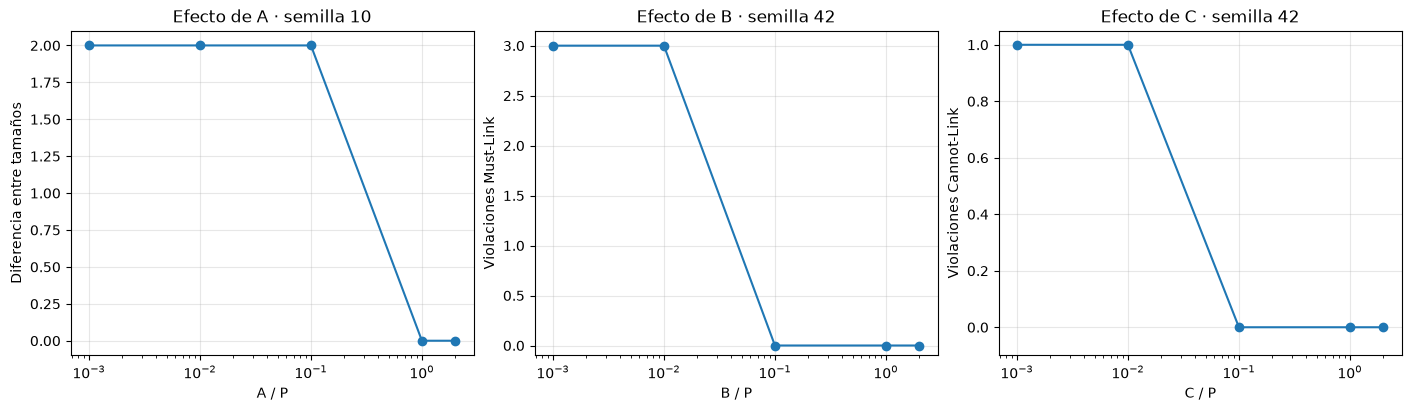

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, parametro in zip(axes, ["A", "B", "C"]):
    datos = [r for r in analisis_parametros if r["parametro"] == parametro]
    campo = {"A": "desbalance", "B": "v_must", "C": "v_cannot"}[parametro]
    etiqueta = {"A": "Diferencia entre tamaños", "B": "Violaciones Must-Link",
                "C": "Violaciones Cannot-Link"}[parametro]
    ax.plot([r["factor"] for r in datos], [r[campo] for r in datos], marker="o")
    ax.set_xscale("log")
    ax.set_xlabel(f"{parametro} / P")
    ax.set_ylabel(etiqueta)
    ax.set_title(f"Efecto de {parametro} · semilla {semillas_parametros[parametro]}")
    ax.set_ylim(bottom=-0.1)
    ax.grid(alpha=0.3)
plt.show()


In [15]:
comentarios_penalizacion = []
for parametro in ["A", "B", "C"]:
    datos = [r for r in analisis_parametros if r["parametro"] == parametro]
    bajo = datos[0]
    referencia = next(r for r in datos if r["factor"] == 1.0)
    if parametro == "A":
        texto = (f"**A bajo (semilla {bajo['semilla']}):** aparecen tamaños {bajo['tamanos']} "
                 f"y corte de peso {bajo['peso_corte']}; con A=P los tamaños son "
                 f"{referencia['tamanos']} y el peso es {referencia['peso_corte']}. "
                 "El mayor corte con A bajo se consigue incumpliendo el balance.")
    else:
        campo = "v_must" if parametro == "B" else "v_cannot"
        texto = (f"**{parametro} bajo (semilla {bajo['semilla']}):** hay {bajo[campo]} "
                 f"violaciones y corte de peso {bajo['peso_corte']}; con {parametro}=P hay "
                 f"{referencia[campo]} violaciones y peso {referencia['peso_corte']}.")
    comentarios_penalizacion.append("- " + texto)
display(Markdown("\n\n".join(comentarios_penalizacion)))


- **A bajo (semilla 10):** aparecen tamaños 3/5 y corte de peso 63; con A=P los tamaños son 4/4 y el peso es 49. El mayor corte con A bajo se consigue incumpliendo el balance.

- **B bajo (semilla 42):** hay 3 violaciones y corte de peso 53; con B=P hay 0 violaciones y peso 39.

- **C bajo (semilla 42):** hay 1 violaciones y corte de peso 42; con C=P hay 0 violaciones y peso 39.

## 3. Comparar distintas instancias del grafo

Se generan cinco grafos de ocho nodos y restricciones aleatorias distintas. Se mantiene **un mismo A=B=C para todas las instancias**, mayor que el peso total de cualquiera de ellas. Ambos métodos resuelven exactamente el mismo QUBO dentro de cada instancia.

La diferencia $\Delta E=E_{SA}-E_{bruta}$ mide la distancia al óptimo de esa instancia. Entre grafos distintos, la energía también depende de sus aristas y restricciones; no basta para ordenar su calidad. Se muestra el número de asignaciones factibles para distinguir incompatibilidad de restricciones de un fallo del método.

In [16]:
semillas_instancias = [10, 21, 42, 67, 99]
instancias_comparacion = [(s, *instancia_analisis(8, s)) for s in semillas_instancias]
P_instancias = 1.0 + max(
    sum(d["weight"] for _, _, d in grafo.edges(data=True))
    for _, grafo, _, _ in instancias_comparacion
)
print(f"Coeficientes comunes de la comparación: A = B = C = {P_instancias:g}")

resultados_instancias = []
filas_instancias = []
sampler_analisis = SimulatedAnnealingSampler()
for semilla_i, grafo_i, ml_i, cl_i in instancias_comparacion:
    modelo_i = modelo_analisis(grafo_i, ml_i, cl_i, P_instancias, P_instancias, P_instancias)
    xb, eb, factibles_i = resolver_fuerza_bruta(modelo_i, ml_i, cl_i)
    muestra_i = sampler_analisis.sample(modelo_i, num_reads=500, num_sweeps=1000, seed=semilla_i).first
    for metodo, xi, ei in [("Fuerza bruta", xb, eb),
                            ("Annealing", muestra_i.sample, muestra_i.energy)]:
        ri = metricas_analisis(grafo_i, ml_i, cl_i, P_instancias, P_instancias, P_instancias, xi, ei)
        ri.update(semilla=semilla_i, metodo=metodo, factibles=factibles_i,
                  gap=max(0.0, float(ei - eb)))
        resultados_instancias.append(ri)
        filas_instancias.append([
            semilla_i, factibles_i, metodo,
            f"{ri['aristas_cortadas']}/{grafo_i.number_of_edges()}", ri["peso_corte"],
            f"{ei:.2f}", ri["tamanos"], ri["violaciones"], f"{ri['gap']:.3f}",
        ])
tabla_analisis(
    ["Semilla", "Factibles", "Método", "Aristas cortadas/total", "Peso corte",
     "E final", "Tamaños", "Violaciones", "ΔE"], filas_instancias
)
incompatibles = sorted({r["semilla"] for r in resultados_instancias if r["factibles"] == 0})
print("Semillas con restricciones incompatibles:", incompatibles or "Ninguna")


Coeficientes comunes de la comparación: A = B = C = 98


| Semilla | Factibles | Método | Aristas cortadas/total | Peso corte | E final | Tamaños | Violaciones | ΔE |
|---|---|---|---|---|---|---|---|---|
| 10 | 2 | Fuerza bruta | 9/16 | 49 | -343.00 | 4/4 | 0 | 0.000 |
| 10 | 2 | Annealing | 9/16 | 49 | -343.00 | 4/4 | 0 | 0.000 |
| 21 | 2 | Fuerza bruta | 9/18 | 40 | -334.00 | 4/4 | 0 | 0.000 |
| 21 | 2 | Annealing | 9/18 | 40 | -334.00 | 4/4 | 0 | 0.000 |
| 42 | 4 | Fuerza bruta | 7/12 | 39 | -333.00 | 4/4 | 0 | 0.000 |
| 42 | 4 | Annealing | 7/12 | 39 | -333.00 | 4/4 | 0 | 0.000 |
| 67 | 0 | Fuerza bruta | 10/15 | 61 | -257.00 | 4/4 | 1 | 0.000 |
| 67 | 0 | Annealing | 10/15 | 61 | -257.00 | 4/4 | 1 | 0.000 |
| 99 | 4 | Fuerza bruta | 5/11 | 34 | -328.00 | 4/4 | 0 | 0.000 |
| 99 | 4 | Annealing | 5/11 | 34 | -328.00 | 4/4 | 0 | 0.000 |

Semillas con restricciones incompatibles: [67]


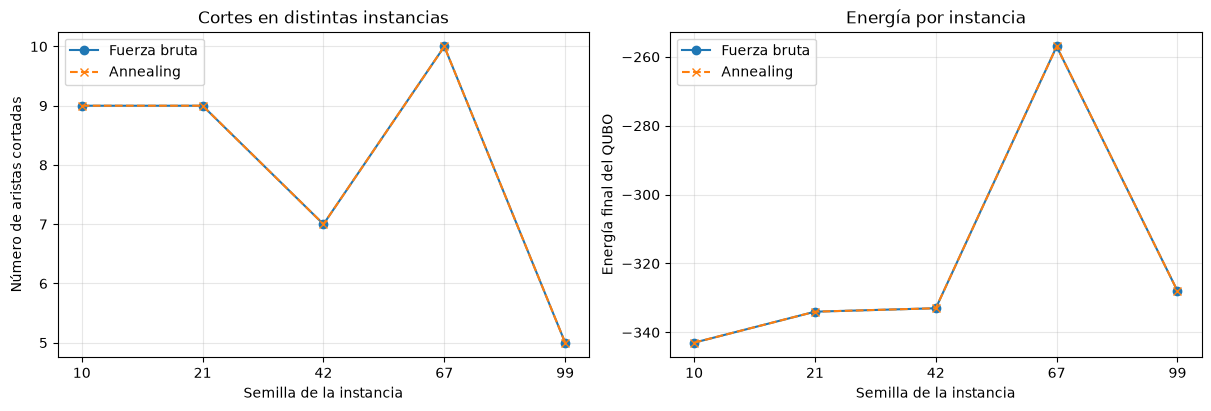

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for metodo, estilo in [("Fuerza bruta", "o-"), ("Annealing", "x--")]:
    datos = [r for r in resultados_instancias if r["metodo"] == metodo]
    posiciones = list(range(len(datos)))
    axes[0].plot(posiciones, [r["aristas_cortadas"] for r in datos], estilo, label=metodo)
    axes[1].plot(posiciones, [r["energia"] for r in datos], estilo, label=metodo)
for ax in axes:
    ax.set_xticks(range(len(semillas_instancias)), [str(s) for s in semillas_instancias])
    ax.set_xlabel("Semilla de la instancia")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Número de aristas cortadas")
axes[0].set_title("Cortes en distintas instancias")
axes[1].set_ylabel("Energía final del QUBO")
axes[1].set_title("Energía por instancia")
plt.show()


## 4. Cómo crece el tiempo al aumentar el número de nodos

Se prueban tamaños de 4 a 16 nodos, con densidad de aristas 0.5 y dos restricciones de cada tipo. Para cada tamaño se genera una instancia y se resuelve tres veces; se presenta la **mediana** del tiempo medida con `perf_counter`.

Se excluyen la generación del grafo, la construcción del QUBO y los gráficos. El tiempo de fuerza bruta incluye la evaluación de todas las asignaciones y el recuento de factibles de la función original. El annealing usa un presupuesto fijo de **200 lecturas y 1000 sweeps por lectura**; su tiempo incluye la llamada al sampler. Ese presupuesto fijo no garantiza la misma calidad al crecer n.

La fuerza bruta explora $2^n$ asignaciones: añadir dos nodos multiplica por cuatro su número. Las mediciones pueden fluctuar por la carga del equipo; se estudia la tendencia, no una monotonía perfecta en cada punto.

In [18]:
tamanos_tiempo = [4, 6, 8, 10, 12, 14, 16]
repeticiones_tiempo = 3
lecturas_tiempo = 200
sweeps_tiempo = 1000
resultados_tiempos = []
filas_tiempos = []
sampler_tiempo = SimulatedAnnealingSampler()

for n_t in tamanos_tiempo:
    grafo_t, ml_t, cl_t = instancia_analisis(n_t, 2026 + n_t, 2, 2)
    P_t = 1.0 + sum(d["weight"] for _, _, d in grafo_t.edges(data=True))
    modelo_t = modelo_analisis(grafo_t, ml_t, cl_t, P_t, P_t, P_t)
    tiempos_bruta, tiempos_sa = [], []
    for repeticion in range(repeticiones_tiempo):
        inicio = perf_counter()
        resolver_fuerza_bruta(modelo_t, ml_t, cl_t)
        tiempos_bruta.append(perf_counter() - inicio)

        inicio = perf_counter()
        sampler_tiempo.sample(modelo_t, num_reads=lecturas_tiempo,
                              num_sweeps=sweeps_tiempo, seed=100 + repeticion)
        tiempos_sa.append(perf_counter() - inicio)

    tb, tsa = median(tiempos_bruta), median(tiempos_sa)
    resultados_tiempos.append({"n": n_t, "asignaciones": 2**n_t,
                              "bruta": tb, "annealing": tsa})
    filas_tiempos.append([n_t, 2**n_t, f"{tb:.6f}", f"{tsa:.6f}"])

tabla_analisis(["n", "Asignaciones fuerza bruta", "Fuerza bruta (s)", "Annealing (s)"], filas_tiempos)


| n | Asignaciones fuerza bruta | Fuerza bruta (s) | Annealing (s) |
|---|---|---|---|
| 4 | 16 | 0.000406 | 0.013083 |
| 6 | 64 | 0.001460 | 0.022743 |
| 8 | 256 | 0.005685 | 0.027326 |
| 10 | 1024 | 0.022462 | 0.030565 |
| 12 | 4096 | 0.092718 | 0.040697 |
| 14 | 16384 | 0.373836 | 0.042216 |
| 16 | 65536 | 1.520294 | 0.054349 |

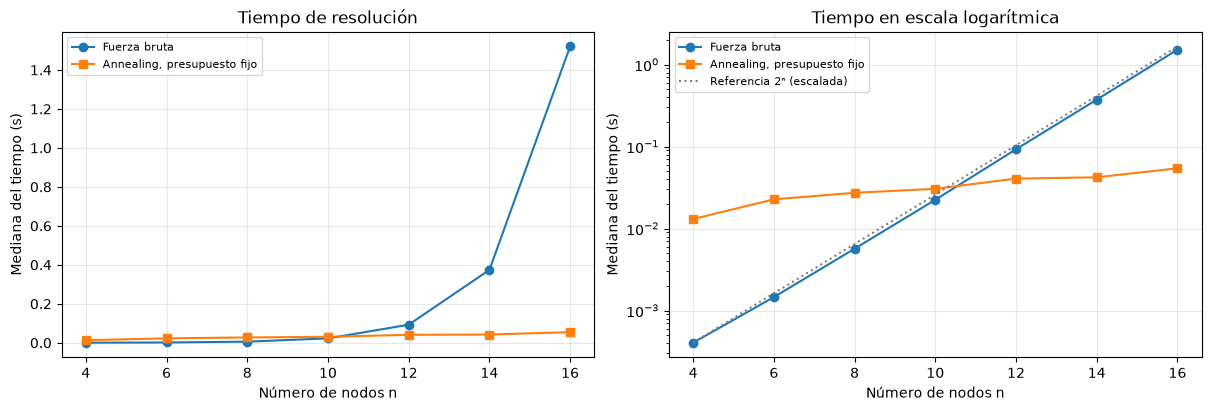

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ns_t = [r["n"] for r in resultados_tiempos]
bruta_t = [r["bruta"] for r in resultados_tiempos]
sa_t = [r["annealing"] for r in resultados_tiempos]
for ax in axes:
    ax.plot(ns_t, bruta_t, "o-", label="Fuerza bruta")
    ax.plot(ns_t, sa_t, "s-", label="Annealing, presupuesto fijo")
    ax.set_xlabel("Número de nodos n")
    ax.set_ylabel("Mediana del tiempo (s)")
    ax.set_xticks(ns_t)
    ax.grid(alpha=0.3)
axes[0].set_title("Tiempo de resolución")
axes[1].set_yscale("log")
axes[1].plot(ns_t, [bruta_t[0] * 2**(k - ns_t[0]) for k in ns_t],
             ":", color="gray", label="Referencia 2ⁿ (escalada)")
axes[1].set_title("Tiempo en escala logarítmica")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()


In [20]:
primera_medida, ultima_medida = resultados_tiempos[0], resultados_tiempos[-1]
crecimiento_tiempo = ultima_medida["bruta"] / primera_medida["bruta"]
crecimiento_estados = ultima_medida["asignaciones"] / primera_medida["asignaciones"]
coincidencias = sum(r["gap"] < 1e-7 for r in resultados_instancias if r["metodo"] == "Annealing")
display(Markdown(
    f"### Conclusiones de los experimentos\n\n"
    f"- Las penalizaciones bajas permiten ganar corte incumpliendo balance o restricciones; "
    f"los barridos muestran los tres casos con semillas explícitas.\n"
    f"- Annealing alcanzó la energía óptima en **{coincidencias} de {len(semillas_instancias)} instancias** "
    f"de esta comparación. Esto es un resultado empírico, no una garantía general.\n"
    f"- De **n={primera_medida['n']}** a **n={ultima_medida['n']}**, las asignaciones se multiplican "
    f"por **{crecimiento_estados:.0f}** y el tiempo mediano de fuerza bruta por "
    f"**{crecimiento_tiempo:.1f}** en esta ejecución. El recuento exponencial explica el crecimiento rápido.\n"
    f"- El tiempo del annealing se ha medido con presupuesto fijo; para comparar métodos a gran escala "
    f"también habría que controlar la probabilidad de alcanzar el óptimo y las violaciones."
))


### Conclusiones de los experimentos

- Las penalizaciones bajas permiten ganar corte incumpliendo balance o restricciones; los barridos muestran los tres casos con semillas explícitas.
- Annealing alcanzó la energía óptima en **5 de 5 instancias** de esta comparación. Esto es un resultado empírico, no una garantía general.
- De **n=4** a **n=16**, las asignaciones se multiplican por **4096** y el tiempo mediano de fuerza bruta por **3744.1** en esta ejecución. El recuento exponencial explica el crecimiento rápido.
- El tiempo del annealing se ha medido con presupuesto fijo; para comparar métodos a gran escala también habría que controlar la probabilidad de alcanzar el óptimo y las violaciones.